In [3]:
import gzip
import json
import random
import zipfile
from pathlib import Path

SAMPLE_SIZE = 100_000
random.seed(42)

zip_path = Path("data/Beauty_and_personal_care.zip")
review_path_in_zip = (
    "Beauty_and_personal_care/Beauty_and_Personal_Care.jsonl.gz"
)

sample_reviews = []

with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(review_path_in_zip) as compressed_file:
        with gzip.GzipFile(fileobj=compressed_file) as f:

            for i, line in enumerate(f):
                review = json.loads(line)

                if i < SAMPLE_SIZE:
                    sample_reviews.append(review)
                else:
                    j = random.randint(0, i)

                    if j < SAMPLE_SIZE:
                        sample_reviews[j] = review

                if (i + 1) % 500_000 == 0:
                    print(f"Processed {(i + 1):,} reviews")

print("\nSampling completed!")
print(f"Number of sampled reviews: {len(sample_reviews):,}")

Processed 500,000 reviews
Processed 1,000,000 reviews
Processed 1,500,000 reviews
Processed 2,000,000 reviews
Processed 2,500,000 reviews
Processed 3,000,000 reviews
Processed 3,500,000 reviews
Processed 4,000,000 reviews
Processed 4,500,000 reviews
Processed 5,000,000 reviews
Processed 5,500,000 reviews
Processed 6,000,000 reviews
Processed 6,500,000 reviews
Processed 7,000,000 reviews
Processed 7,500,000 reviews
Processed 8,000,000 reviews
Processed 8,500,000 reviews
Processed 9,000,000 reviews
Processed 9,500,000 reviews
Processed 10,000,000 reviews
Processed 10,500,000 reviews
Processed 11,000,000 reviews
Processed 11,500,000 reviews
Processed 12,000,000 reviews
Processed 12,500,000 reviews
Processed 13,000,000 reviews
Processed 13,500,000 reviews
Processed 14,000,000 reviews
Processed 14,500,000 reviews
Processed 15,000,000 reviews
Processed 15,500,000 reviews
Processed 16,000,000 reviews
Processed 16,500,000 reviews
Processed 17,000,000 reviews
Processed 17,500,000 reviews
Proces

In [4]:
from pathlib import Path
import pandas as pd

# Create a folder for saving the sample
save_path = Path("data/extracted")
save_path.mkdir(parents=True, exist_ok=True)

# Convert the sample to a DataFrame
reviews_df = pd.DataFrame(sample_reviews)

# Save the sample
file_path = save_path / "reviews_sample_100k.pkl"

reviews_df.to_pickle(file_path)

# Verify the saved file
print("Saved successfully:", file_path.exists())
print("File size:", round(file_path.stat().st_size / (1024**2), 2), "MB")
print("Number of reviews:", len(reviews_df))

Saved successfully: True
File size: 33.22 MB
Number of reviews: 100000


ذخیره ی دیتاست قابل اپلود

در ابتدا سعی میکنیم 100000 دیتا به صورت کاملا تصادفی از ریویو ها جدا کنیم چون ظرفیت پردازش کل دیتاست رو در حال حاضر نداریم در نتیجه دیتا ستی کوچکتر به صورت تصادفی میسازیم و ان را با شناسه ی والد محصول میتوانیم با متا دیتا هم یکسان کنیم.

یکسان سازی دیتاست ریویو ها با متا

In [9]:
from pathlib import Path
import pandas as pd

# Extract unique product IDs
product_ids = reviews_df["parent_asin"].dropna().unique()
save_path = Path("data/extracted")
save_path.mkdir(parents=True, exist_ok=True)

print("Number of sampled reviews:", len(reviews_df))
print("Number of unique products:", len(product_ids))

print("\nFirst 10 product IDs:")
print(product_ids[:10])

Number of sampled reviews: 100000
Number of unique products: 55902

First 10 product IDs:
<ArrowStringArray>
['B001FUBS5K', 'B00PF9Q5EG', 'B009GA5XVG', 'B0721RHFVG', 'B09F714KGL',
 'B0C58QB9FW', 'B07N99KBXW', 'B086PBGYND', 'B01KKZHGC4', 'B08XY82146']
Length: 10, dtype: str


In [27]:
import gzip
import json
import random
import zipfile
from pathlib import Path
meta_sample = []
meta_path_in_zip = (
    "Beauty_and_personal_care/meta_Beauty_and_Personal_Care.jsonl.gz"
)
with zipfile.ZipFile(zip_path, "r") as z:
    with z.open(meta_path_in_zip, "r") as compressed_file:
        with gzip.GzipFile(fileobj=compressed_file) as f:
            i=0;
            for line in f:
                metadata = json.loads(line)

                if metadata.get("parent_asin") in product_ids:
                    meta_sample.append(metadata)
                if(i%10000 ==0) :
                    print("prosec ")
                    print(i)
                i=i+1
            

print("Metadata extraction completed!")
print("Number of metadata records:", len(meta_sample))

prosec 
0
prosec 
10000
prosec 
20000
prosec 
30000
prosec 
40000
prosec 
50000
prosec 
60000
prosec 
70000
prosec 
80000
prosec 
90000
prosec 
100000
prosec 
110000
prosec 
120000
prosec 
130000
prosec 
140000
prosec 
150000
prosec 
160000
prosec 
170000
prosec 
180000
prosec 
190000
prosec 
200000
prosec 
210000
prosec 
220000
prosec 
230000
prosec 
240000
prosec 
250000
prosec 
260000
prosec 
270000
prosec 
280000
prosec 
290000
prosec 
300000
prosec 
310000
prosec 
320000
prosec 
330000
prosec 
340000
prosec 
350000
prosec 
360000
prosec 
370000
prosec 
380000
prosec 
390000
prosec 
400000
prosec 
410000
prosec 
420000
prosec 
430000
prosec 
440000
prosec 
450000
prosec 
460000
prosec 
470000
prosec 
480000
prosec 
490000
prosec 
500000
prosec 
510000
prosec 
520000
prosec 
530000
prosec 
540000
prosec 
550000
prosec 
560000
prosec 
570000
prosec 
580000
prosec 
590000
prosec 
600000
prosec 
610000
prosec 
620000
prosec 
630000
prosec 
640000
prosec 
650000
prosec 
660000
prosec 
6

ذخیره ی دیتاست متا:

In [29]:
from pathlib import Path
import pandas as pd

save_path = Path("data/extracted")
save_path.mkdir(parents=True, exist_ok=True)

# Convert the sample to a DataFrame
meta_df = pd.DataFrame(meta_sample)

# Save the sample
file_path = save_path / "metas_samples.pkl"

meta_df.to_pickle(file_path)

# Verify the saved file
print("Saved successfully:", file_path.exists())
print("File size:", round(file_path.stat().st_size / (1024**2), 2), "MB")
print("Number of meta:", len(meta_df))

Saved successfully: True
File size: 173.55 MB
Number of meta: 55902


از اینجا ران بشههه:

باز کردن دیتا ست سمپل ها هم متا و هم ریویو

In [4]:
import pandas as pd

file_path = "data/extracted/reviews_sample_100k.pkl"

reviews_df = pd.read_pickle(file_path)

print("Number of reviews:", len(reviews_df))
reviews_df.head()

Number of reviews: 100000


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
0,4.0,Good but...,I like the concept of this a lot and it works ...,[],B001FUBS5K,B001FUBS5K,AHX46DHDWT3EWIGZL73EVWAIHKPQ,1401214324000,0,True
1,2.0,Wouldn't buy again,Peels off within days,[],B00PF9Q5EG,B00PF9Q5EG,AFVVPTSROUQQHFTOVXQ4LNDIQ2YQ,1491877013000,0,True
2,3.0,Didn’t really work that good.,Had higher hopes for this product. Didn’t real...,[],B009GA5XVG,B009GA5XVG,AHJ7TZF6TKQS26FOO5AN7KGCNXHQ,1522702812287,1,True
3,5.0,Great product for great price,Great product for great price,[],B0721RHFVG,B0721RHFVG,AF5EYV5LR3JXYTFYE3FC3BSFUO2Q,1578485994079,0,True
4,5.0,Easy to remove no hussle,I love this product very effective,[],B0121SN1QI,B09F714KGL,AFEKDR72LCN7GYRPGKIYVSDGOSVA,1574344461968,0,True


In [2]:
import pandas as pd

file_path = "data/extracted/metas_samples.pkl"

meta_df = pd.read_pickle(file_path)

print("Number of reviews:", len(meta_df))
meta_df.head()

Number of reviews: 55902


,main_category,title,average_rating,rating_number,features,description,price,images,videos,store,categories,details,parent_asin,bought_together,subtitle,author
0,All Beauty,"L.A. COLORS 5 Color Matte Eyeshadow, Brown Twe...",4.3,5367,"[Intense color, Matte finish, Silky texture]","[Wrap yourself in soft, cozy color. These matt...",2.49,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'LA Colors Pallete Review - YOU MUS...,L.A. COLORS,"[Beauty & Personal Care, Makeup, Eyes, Eyeshadow]","{'Color': 'Brown Tweed', 'Brand': 'L.A. COLORS...",B01DX1OEFO,None,NaN,NaN
1,All Beauty,Paloma Picasso for Women By Paloma Picasso 6.7...,4.2,85,"[100% Genuine Guaranteed, Safety & Security Gu...",[BODY LOTION 6.7 OZ for female],None,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Paloma Picasso Full Fragrance Revi...,Paloma Picasso,"[Beauty & Personal Care, Skin Care, Body, Mois...","{'Brand': 'Paloma Picasso', 'Scent': 'Citrus',...",B000M86E3C,None,NaN,NaN
2,All Beauty,Newcally Natural Look Lashes Mink 3D Fluffy Wi...,4.4,34981,[The natural false eyelashes are fluffy and so...,[],9.45,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'My favorite lashes ', 'url': 'http...",Newcally,"[Beauty & Personal Care, Tools & Accessories, ...","{'Color': 'Black', 'Brand': 'Newcally', 'Mater...",B09WHMND5W,None,NaN,NaN
3,Health & Personal Care,Babo Botanicals Sheer Zinc Continuous Spray Su...,4.3,4526,[100% GOOD FOR YOU & YOUR FAMILY: A fast-absor...,[Get the comfort of a lotion sunscreen and the...,18.99,[{'thumb': 'https://m.media-amazon.com/images/...,"[{'title': 'Be Aware! Very Watery, Do Not Reco...",Babo Botanicals,"[Beauty & Personal Care, Skin Care, Sunscreens...","{'Scent': 'Unscented', 'Product Benefits': 'Fa...",B01ALT5MKW,None,NaN,NaN
4,All Beauty,Eau De Private Collection By Estee Lauder Frag...,4.4,133,[Eau De Private Collection By Estee Lauder Fra...,[Eau De Private Collection By Estee Lauder Fra...,69.49,[{'thumb': 'https://m.media-amazon.com/images/...,[{'title': 'Estee Lauder Beautiful Women Spray...,Estee Lauder,"[Beauty & Personal Care, Fragrance, Women's, E...","{'Brand': 'Estee Lauder', 'Item Form': 'Aeroso...",B00098FI9G,None,NaN,NaN


ممیزی ساختار داده ها

In [5]:
# Structural audit of the Reviews dataset

print("Number of rows:", reviews_df.shape[0])
print("Number of columns:", reviews_df.shape[1])

print("\nColumn names:")
print(reviews_df.columns.tolist())

print("\nData types:")
display(reviews_df.dtypes.to_frame("Data Type"))

print("\nIdentifier columns:")
display(
    reviews_df[
        ["user_id", "asin", "parent_asin"]
    ].head()
)

print("\nTemporal variable:")
display(reviews_df[["timestamp"]].head())

Number of rows: 100000
Number of columns: 10

Column names:
['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']

Data types:


,Data Type
rating,float64
title,str
text,str
images,object
asin,str
parent_asin,str
user_id,str
timestamp,int64
helpful_vote,int64
verified_purchase,bool



Identifier columns:


,user_id,asin,parent_asin
0,AHX46DHDWT3EWIGZL73EVWAIHKPQ,B001FUBS5K,B001FUBS5K
1,AFVVPTSROUQQHFTOVXQ4LNDIQ2YQ,B00PF9Q5EG,B00PF9Q5EG
2,AHJ7TZF6TKQS26FOO5AN7KGCNXHQ,B009GA5XVG,B009GA5XVG
3,AF5EYV5LR3JXYTFYE3FC3BSFUO2Q,B0721RHFVG,B0721RHFVG
4,AFEKDR72LCN7GYRPGKIYVSDGOSVA,B0121SN1QI,B09F714KGL



Temporal variable:


,timestamp
0,1401214324000
1,1491877013000
2,1522702812287
3,1578485994079
4,1574344461968


In [7]:
# Structural audit of the Metadata dataset

print("Number of rows:", meta_df.shape[0])
print("Number of columns:", meta_df.shape[1])

print("\nColumn names:")
print(meta_df.columns.tolist())

print("\nData types:")
display(meta_df.dtypes.to_frame("Data Type"))

print("\nIdentifier column: parent_asin")
display(meta_df[["parent_asin"]].head())

print("\nIdentifier summary:")
print("Number of unique parent_asin:", meta_df["parent_asin"].nunique())
print("Number of missing parent_asin:", meta_df["parent_asin"].isna().sum())
print("Number of duplicated parent_asin:", meta_df["parent_asin"].duplicated().sum())

print("\nTemporal variables:")
time_columns = [
    col for col in meta_df.columns
    if any(keyword in col.lower() for keyword in ["time", "date", "year", "month"])
]

if time_columns:
    display(meta_df[time_columns].head())
else:
    print("No explicit temporal variables found.")

Number of rows: 55902
Number of columns: 16

Column names:
['main_category', 'title', 'average_rating', 'rating_number', 'features', 'description', 'price', 'images', 'videos', 'store', 'categories', 'details', 'parent_asin', 'bought_together', 'subtitle', 'author']

Data types:


,Data Type
main_category,str
title,str
average_rating,float64
rating_number,int64
features,object
description,object
price,object
images,object
videos,object
store,str



Identifier column: parent_asin


,parent_asin
0,B01DX1OEFO
1,B000M86E3C
2,B09WHMND5W
3,B01ALT5MKW
4,B00098FI9G



Identifier summary:
Number of unique parent_asin: 55902
Number of missing parent_asin: 0
Number of duplicated parent_asin: 0

Temporal variables:
No explicit temporal variables found.


ممیزی کیفیت داده ها

1. میسینگ ولیو ها:

In [9]:
import pandas as pd
import numpy as np

def audit_dataset(df, dataset_name):

    audit_results = []

    for col in df.columns:

        series = df[col]

        # Missing values
        missing_count = series.isna().sum()
        missing_percent = (missing_count / len(df)) * 100

        # Empty strings
        empty_strings = (
            series.apply(lambda x: isinstance(x, str) and x.strip() == "")
        ).sum()

        # Empty lists, dictionaries, etc.
        empty_collections = series.apply(
            lambda x: isinstance(x, (list, dict, tuple, set)) and len(x) == 0
        ).sum()

        # Unique values (robust for lists/dictionaries)
        unique_count = series.dropna().apply(
            lambda x: repr(x)
        ).nunique()

        # Data type
        data_type = str(series.dtype)

        audit_results.append({
            "Column": col,
            "Data Type": data_type,
            "Missing Count": missing_count,
            "Missing (%)": round(missing_percent, 2),
            "Empty Strings": empty_strings,
            "Empty Collections": empty_collections,
            "Unique Values": unique_count
        })

    audit_df = pd.DataFrame(audit_results)

    print(f"\n{'='*60}")
    print(f"DATA QUALITY AUDIT: {dataset_name}")
    print(f"{'='*60}")

    display(audit_df)

    return audit_df


# Audit Metadata
metadata_quality = audit_dataset(meta_df, "Metadata")

# Audit Reviews
reviews_quality = audit_dataset(reviews_df, "Reviews")


DATA QUALITY AUDIT: Metadata


,Column,Data Type,Missing Count,Missing (%),Empty Strings,Empty Collections,Unique Values
0,main_category,str,1762,3.15,0,0,29
1,title,str,0,0.00,4,0,55576
2,average_rating,float64,0,0.00,0,0,40
3,rating_number,int64,0,0.00,0,0,8558
4,features,object,0,0.00,0,9431,45078
5,description,object,0,0.00,0,27743,26936
6,price,object,21893,39.16,0,0,4344
7,images,object,0,0.00,0,3,55586
8,videos,object,0,0.00,0,22401,32816
9,store,str,3410,6.10,0,0,18657



DATA QUALITY AUDIT: Reviews


,Column,Data Type,Missing Count,Missing (%),Empty Strings,Empty Collections,Unique Values
0,rating,float64,0,0.0,0,0,5
1,title,str,0,0.0,0,0,63583
2,text,str,0,0.0,141,0,94787
3,images,object,0,0.0,0,92854,7145
4,asin,str,0,0.0,0,0,64655
5,parent_asin,str,0,0.0,0,0,55902
6,user_id,str,0,0.0,0,0,98245
7,timestamp,int64,0,0.0,0,0,99988
8,helpful_vote,int64,0,0.0,0,0,171
9,verified_purchase,bool,0,0.0,0,0,2


تصمیم گیری در مورد داده های گمشده
1. متادیتا
ستون 13 14 و 15 متادیتا رو حذف میکنیم چون کاملا خالی اند.
ستون 0 و 9 رو با unknown پر میکنیم
ستون قیمت را میتوان با میانگین قیمت در اون کتگوری پر کرد؟ احتمالا 
تصاویر و ویدیو و دیتیل های خالی خیلی اهمیتی در مدل ندارند. و شاید تاثیر گذار باشند روی نوع نقد و پیش بینی روی محصولات اینده در نتیجه حذفشون منطقی نیست.
2. ریویو: 
ستون تصاویر و ویدیو ها خیلی اهمیتی  نداره و شاید نبودشون روی ریویو اثر بزاره در نتیجه حذف این ستون ها خطای تحلیلی ایجاد میکنه
ستون تکست رو چون درصد خیلی کمی از  کل دیتاست رو میتوان ردیف های بدون متن رو حذف کرد. 

In [10]:

import pandas as pd
import numpy as np
from pathlib import Path

# ==========================================
# INITIAL DATA CLEANING
# ==========================================

# Keep original datasets unchanged
reviews_clean = reviews_df.copy()
meta_clean = meta_df.copy()

# ------------------------------------------
# 1. METADATA: Drop columns with >90% missing
# ------------------------------------------

metadata_columns_to_drop = [
    "bought_together",
    "subtitle",
    "author"
]

meta_clean = meta_clean.drop(
    columns=metadata_columns_to_drop,
    errors="ignore"
)

print("Dropped Metadata columns:", metadata_columns_to_drop)

# ------------------------------------------
# 2. METADATA: Fill missing main_category/store
# ------------------------------------------

for col in ["main_category", "store"]:
    if col in meta_clean.columns:
        meta_clean[col] = meta_clean[col].fillna("Unknown")

# ------------------------------------------
# 3. METADATA: Convert empty title strings to NaN
# ------------------------------------------

meta_clean["title"] = meta_clean["title"].replace(
    r"^\s*$",
    np.nan,
    regex=True
)

# ------------------------------------------
# 4. REVIEWS: Remove empty review text
# ------------------------------------------

empty_text_mask = (
    reviews_clean["text"]
    .astype(str)
    .str.strip()
    .eq("")
)

removed_reviews_count = empty_text_mask.sum()

reviews_clean = reviews_clean.loc[
    ~empty_text_mask
].copy()

print("Removed Reviews with empty text:", removed_reviews_count)

# ------------------------------------------
# 5. Preserve optional images/videos/details
# ------------------------------------------
# No rows or columns are removed for empty
# images, videos, features, description, or details.

# ------------------------------------------
# 6. Summary
# ------------------------------------------

print("\n" + "=" * 50)
print("CLEANING SUMMARY")
print("=" * 50)

print("Original Reviews shape:", reviews_df.shape)
print("Cleaned Reviews shape:", reviews_clean.shape)

print("Original Metadata shape:", meta_df.shape)
print("Cleaned Metadata shape:", meta_clean.shape)

# ------------------------------------------
# 7. Save cleaned datasets
# ------------------------------------------

output_dir = Path("data/extracted")
output_dir.mkdir(parents=True, exist_ok=True)

reviews_clean.to_pickle(
    output_dir / "reviews_clean.pkl"
)

meta_clean.to_pickle(
    output_dir / "metadata_clean.pkl"
)

print("\nCleaned datasets saved successfully!")



Dropped Metadata columns: ['bought_together', 'subtitle', 'author']
Removed Reviews with empty text: 141

CLEANING SUMMARY
Original Reviews shape: (100000, 10)
Cleaned Reviews shape: (99859, 10)
Original Metadata shape: (55902, 16)
Cleaned Metadata shape: (55902, 13)

Cleaned datasets saved successfully!


2. رکوردهای تکراری:
   

In [12]:

# Cell 1: Duplicate Audit

# تبدیل مقادیر لیستی و دیکشنری به فرم قابل مقایسه
def make_hashable(value):
    if isinstance(value, list):
        return tuple(make_hashable(item) for item in value)
    elif isinstance(value, dict):
        return tuple(
            sorted((key, make_hashable(val)) for key, val in value.items())
        )
    elif isinstance(value, set):
        return tuple(sorted(make_hashable(item) for item in value))
    else:
        return value


# 1. بررسی تکرار کامل ردیف‌ها
reviews_hashable = reviews_clean.map(make_hashable)
meta_hashable = meta_clean.map(make_hashable)

reviews_full_duplicates = reviews_hashable.duplicated().sum()
meta_full_duplicates = meta_hashable.duplicated().sum()


# 2. بررسی تکرار Reviews بر اساس user_id و parent_asin
reviews_user_product_duplicates = reviews_clean.duplicated(
    subset=["user_id", "parent_asin"],
    keep=False
).sum()


# 3. بررسی تکرار شناسه محصول در Metadata
meta_parent_asin_duplicates = meta_clean["parent_asin"].duplicated().sum()


print("=== Duplicate Audit ===")

print(f"Reviews - Full duplicate rows: {reviews_full_duplicates}")
print(f"Metadata - Full duplicate rows: {meta_full_duplicates}")

print(
    "Reviews - Rows involved in repeated user-product pairs:",
    reviews_user_product_duplicates
)

print(
    "Metadata - Duplicate parent_asin values:",
    meta_parent_asin_duplicates
)


# نمایش نمونه ردیف‌های تکراری کامل
if reviews_full_duplicates > 0:
    display(
        reviews_clean[
            reviews_hashable.duplicated(keep=False)
        ].head(10)
    )

if meta_full_duplicates > 0:
    display(
        meta_clean[
            meta_hashable.duplicated(keep=False)
        ].head(10)
    )


# نمایش نمونه user-product pairs تکراری
if reviews_user_product_duplicates > 0:
    display(
        reviews_clean[
            reviews_clean.duplicated(
                subset=["user_id", "parent_asin"],
                keep=False
            )
        ][["user_id", "parent_asin", "rating", "timestamp"]].head(10)
    )


=== Duplicate Audit ===
Reviews - Full duplicate rows: 7
Metadata - Full duplicate rows: 0
Reviews - Rows involved in repeated user-product pairs: 20
Metadata - Duplicate parent_asin values: 0


,rating,title,text,images,asin,parent_asin,user_id,timestamp,helpful_vote,verified_purchase
1095,1.0,Color is just grey. No lunimessance at all,Not color shown,[{'small_image_url': 'https://images-na.ssl-im...,B07DSB22RP,B07DSB22RP,AFD327ABM7NEDN7Z2FLYSUKHK5RA,1626127558301,0,True
17396,1.0,Color is just grey. No lunimessance at all,Not color shown,[{'small_image_url': 'https://images-na.ssl-im...,B07DSB22RP,B07DSB22RP,AFD327ABM7NEDN7Z2FLYSUKHK5RA,1626127558301,0,True
38828,5.0,Great product,This lash remover was really good! I applied i...,[],B072JTNVHB,B0BS3YH9ZP,AGROW7UQMF3WGGGP6GVHB4BPIHQA,1610735562185,0,True
40316,5.0,"Recommend it, worth it",Totally worked and will last months with one a...,[],B00JC5WTOO,B00JC5WTOO,AEKYD7EBODN4CTGYNLS4Y7RT4DFA,1611522198370,0,False
43287,5.0,doesn't come with charging block only USB cable,"Love this product, best part travel friendly p...",[],B08NX1QJ3Q,B0BGJXYKRZ,AHA44JCLSRFE3JADJKMEEGFRLTHQ,1672541874685,0,True
47237,5.0,"Recommend it, worth it",Totally worked and will last months with one a...,[],B00JC5WTOO,B00JC5WTOO,AEKYD7EBODN4CTGYNLS4Y7RT4DFA,1611522198370,0,False
75422,1.0,Quality,This hair is not good quality. The hair sheds ...,[],B07ML3G557,B07ML3G557,AFWNQSEJXYU2EJM2Q77O4X2KSUVA,1569696256284,0,True
76610,3.0,Ink bleeds into skin cracks,Used this product for drawing art on skin. W c...,[],B009FWZ2RU,B08MFZ9169,AFWG554FDVUANPLOV2JFNZ4PHGNQ,1578540744767,1,True
81185,2.0,not as amazing as others expressed in terms of...,Its ok! not as amazing as others expressed in ...,[],B00PJB95X8,B07C7HKZ8R,AHFR44IQ5NMP3BDWP3ADQLFOWIZQ,1525013092884,0,True
81193,1.0,Quality,This hair is not good quality. The hair sheds ...,[],B07ML3G557,B07ML3G557,AFWNQSEJXYU2EJM2Q77O4X2KSUVA,1569696256284,0,True


,user_id,parent_asin,rating,timestamp
1095,AFD327ABM7NEDN7Z2FLYSUKHK5RA,B07DSB22RP,1.0,1626127558301
17396,AFD327ABM7NEDN7Z2FLYSUKHK5RA,B07DSB22RP,1.0,1626127558301
23859,AGHTN7YAXNHKIKGEWBRFCKAW2TRA,B00HFG0FAM,5.0,1442253038000
38828,AGROW7UQMF3WGGGP6GVHB4BPIHQA,B0BS3YH9ZP,5.0,1610735562185
40316,AEKYD7EBODN4CTGYNLS4Y7RT4DFA,B00JC5WTOO,5.0,1611522198370
43287,AHA44JCLSRFE3JADJKMEEGFRLTHQ,B0BGJXYKRZ,5.0,1672541874685
44852,AEMSBC62FNUDZN2KTGAGUG5KGXQQ,B00JJKHS3O,2.0,1365882676000
47237,AEKYD7EBODN4CTGYNLS4Y7RT4DFA,B00JC5WTOO,5.0,1611522198370
59194,AGNUSAX2AQAJ634S5G32J4YFNW6A,B0BWNHG7MX,1.0,1500302922783
69842,AEMSBC62FNUDZN2KTGAGUG5KGXQQ,B00JJKHS3O,2.0,1365882679000


حذف ردیف های تکراری:

In [14]:
reviews_clean = reviews_clean.drop_duplicates(
    subset=[
        "rating", "title", "text", "asin",
        "parent_asin", "user_id", "timestamp",
        "helpful_vote", "verified_purchase"
    ]
).reset_index(drop=True)

3. مقادیر ناممکن:

In [16]:
import pandas as pd
import numpy as np

# ==========================================
# Comprehensive Invalid Values Audit
# ==========================================

def show_invalid(name, mask, df, column):
    mask = mask.fillna(False)
    count = mask.sum()

    print(f"{name}: {count}")

    if count > 0:
        print("Examples:")
        print(df.loc[mask, column].head(5).to_list())


# ==========================================
# Reviews Dataset
# ==========================================

print("========== REVIEWS AUDIT ==========")

# 1. Rating: must be between 1 and 5
show_invalid(
    "Invalid ratings",
    ~reviews_clean["rating"].isin([1, 2, 3, 4, 5]),
    reviews_clean,
    "rating"
)

# 2. Title: empty or non-string values
show_invalid(
    "Invalid titles",
    reviews_clean["title"].notna() &
    (
        ~reviews_clean["title"].apply(lambda x: isinstance(x, str)) |
        reviews_clean["title"].apply(
            lambda x: isinstance(x, str) and x.strip() == ""
        )
    ),
    reviews_clean,
    "title"
)

# 3. Text: empty or non-string values
show_invalid(
    "Invalid review texts",
    reviews_clean["text"].notna() &
    (
        ~reviews_clean["text"].apply(lambda x: isinstance(x, str)) |
        reviews_clean["text"].apply(
            lambda x: isinstance(x, str) and x.strip() == ""
        )
    ),
    reviews_clean,
    "text"
)

# 4. ASIN identifiers: empty strings
for col in ["asin", "parent_asin", "user_id"]:
    show_invalid(
        f"Invalid {col}",
        reviews_clean[col].notna() &
        reviews_clean[col].astype(str).str.strip().eq(""),
        reviews_clean,
        col
    )

# 5. Timestamp: plausible Unix milliseconds
timestamp = pd.to_numeric(
    reviews_clean["timestamp"],
    errors="coerce"
)

show_invalid(
    "Invalid timestamps",
    timestamp.isna() |
    (timestamp < 631152000000) |
    (timestamp > 1800000000000),
    reviews_clean,
    "timestamp"
)

# 6. Helpful votes: must be non-negative integers
helpful = pd.to_numeric(
    reviews_clean["helpful_vote"],
    errors="coerce"
)

show_invalid(
    "Invalid helpful_vote",
    helpful.isna() |
    (helpful < 0) |
    (helpful % 1 != 0),
    reviews_clean,
    "helpful_vote"
)

# 7. Verified purchase: Boolean values
show_invalid(
    "Invalid verified_purchase",
    ~reviews_clean["verified_purchase"].isin([True, False]),
    reviews_clean,
    "verified_purchase"
)


# ==========================================
# Metadata Dataset
# ==========================================

print("\n========== METADATA AUDIT ==========")

# 1. Average rating: between 0 and 5
avg_rating = pd.to_numeric(
    meta_clean["average_rating"],
    errors="coerce"
)

show_invalid(
    "Invalid average_rating",
    avg_rating.isna() |
    (avg_rating < 0) |
    (avg_rating > 5),
    meta_clean,
    "average_rating"
)

# 2. Rating number: non-negative integer
rating_number = pd.to_numeric(
    meta_clean["rating_number"],
    errors="coerce"
)

show_invalid(
    "Invalid rating_number",
    rating_number.isna() |
    (rating_number < 0) |
    (rating_number % 1 != 0),
    meta_clean,
    "rating_number"
)

# 3. Price: non-negative numeric values
price_numeric = pd.to_numeric(
    meta_clean["price"].astype(str)
    .str.replace(r"[$,]", "", regex=True)
    .str.strip(),
    errors="coerce"
)

show_invalid(
    "Invalid prices",
    meta_clean["price"].notna() &
    (
        price_numeric.isna() |
        (price_numeric < 0)
    ),
    meta_clean,
    "price"
)

# 4. Title: empty strings
show_invalid(
    "Invalid metadata titles",
    meta_clean["title"].notna() &
    meta_clean["title"].astype(str).str.strip().eq(""),
    meta_clean,
    "title"
)

# 5. Parent ASIN: empty strings
show_invalid(
    "Invalid metadata parent_asin",
    meta_clean["parent_asin"].notna() &
    meta_clean["parent_asin"].astype(str).str.strip().eq(""),
    meta_clean,
    "parent_asin"
)

# 6. Main category: empty strings
show_invalid(
    "Invalid main_category",
    meta_clean["main_category"].notna() &
    meta_clean["main_category"].astype(str).str.strip().eq(""),
    meta_clean,
    "main_category"
)

# 7. Store: empty strings
show_invalid(
    "Invalid store",
    meta_clean["store"].notna() &
    meta_clean["store"].astype(str).str.strip().eq(""),
    meta_clean,
    "store"
)

print("\nAudit completed.")

========== REVIEWS AUDIT ==========
Invalid ratings: 0
Invalid titles: 0
Invalid review texts: 0
Invalid asin: 0
Invalid parent_asin: 0
Invalid user_id: 0
Invalid timestamps: 0
Invalid helpful_vote: 0
Invalid verified_purchase: 0

========== METADATA AUDIT ==========
Invalid average_rating: 0
Invalid rating_number: 0
Invalid prices: 1
Examples:
['from 28.10']
Invalid metadata titles: 0
Invalid metadata parent_asin: 0
Invalid main_category: 0
Invalid store: 0

Audit completed.


قیمت ناممکن:

In [18]:
# ==========================================
# Investigate Price Formats
# ==========================================

print("=== Original Price Missing Values ===")
print(meta_clean["price"].isna().sum())

print("\n=== Most Common Original Price Formats ===")
print(meta_clean["price"].value_counts(dropna=False).head(30))

print("\n=== Non-missing prices that failed numeric conversion ===")

failed_prices = meta_clean[
    meta_clean["price"].notna() &
    meta_clean["price_numeric"].isna()
]

print("Count:", len(failed_prices))

print("\nExamples:")
print(failed_prices["price"].value_counts().head(30))

print("\n=== All distinct failed price formats ===")
print(failed_prices["price"].drop_duplicates().head(50).to_list())

=== Original Price Missing Values ===
21893

=== Most Common Original Price Formats ===
price
None     21893
9.99      1629
7.99       834
11.99      829
8.99       802
6.99       789
19.99      661
14.99      624
12.99      505
13.99      497
5.99       469
15.99      460
16.99      374
29.99      374
17.99      352
18.99      304
4.99       293
24.99      286
39.99      266
21.99      263
10.99      262
22.99      208
25.99      204
12.0       185
23.99      177
26.99      159
18.0       150
49.99      149
24.0       148
25.0       145
Name: count, dtype: int64

=== Non-missing prices that failed numeric conversion ===
Count: 0

Examples:
Series([], Name: count, dtype: int64)

=== All distinct failed price formats ===
[]


4. ناسازگاری نوع  داده ها 

5. نمونه های پرت : 

In [19]:

# ==========================================
# Outlier Audit - Reviews
# ==========================================

import pandas as pd
import numpy as np

def iqr_outlier_audit(df, column):
    data = pd.to_numeric(df[column], errors="coerce").dropna()

    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = data[(data < lower_bound) | (data > upper_bound)]

    print(f"\nColumn: {column}")
    print(f"Q1: {Q1}")
    print(f"Q3: {Q3}")
    print(f"IQR: {IQR}")
    print(f"Lower bound: {lower_bound}")
    print(f"Upper bound: {upper_bound}")
    print(f"Number of outliers: {len(outliers)}")
    print(f"Percentage of outliers: {len(outliers) / len(data) * 100:.2f}%")

    print("\nLargest values:")
    print(data.nlargest(10).to_list())


# Helpful votes
iqr_outlier_audit(reviews_clean, "helpful_vote")

# Timestamp
iqr_outlier_audit(reviews_clean, "timestamp")



Column: helpful_vote
Q1: 0.0
Q3: 1.0
IQR: 1.0
Lower bound: -1.5
Upper bound: 2.5
Number of outliers: 7825
Percentage of outliers: 7.84%

Largest values:
[1459, 1434, 1428, 794, 767, 761, 652, 611, 578, 504]

Column: timestamp
Q1: 1499666910047.5
Q3: 1634765627447.25
IQR: 135098717399.75
Lower bound: 1297018833947.875
Upper bound: 1837413703546.875
Number of outliers: 452
Percentage of outliers: 0.45%

Largest values:
[1694130058074, 1693854263174, 1693849869438, 1693782816111, 1693776169999, 1693766571413, 1693703267407, 1693635087640, 1693604777041, 1693596637570]


In [20]:

# ==========================================
# Outlier Audit - Metadata
# ==========================================

# Price
iqr_outlier_audit(meta_clean, "price_numeric")

# Average rating
iqr_outlier_audit(meta_clean, "average_rating")

# Rating number
iqr_outlier_audit(meta_clean, "rating_number")



Column: price_numeric
Q1: 9.99
Q3: 27.0
IQR: 17.009999999999998
Lower bound: -15.524999999999997
Upper bound: 52.515
Number of outliers: 2860
Percentage of outliers: 8.41%

Largest values:
[3799.0, 3398.0, 2499.0, 2199.0, 1999.99, 1699.99, 1699.0, 1699.0, 1689.99, 1509.03]

Column: average_rating
Q1: 4.1
Q3: 4.6
IQR: 0.5
Lower bound: 3.3499999999999996
Upper bound: 5.35
Number of outliers: 2473
Percentage of outliers: 4.42%

Largest values:
[5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0, 5.0]

Column: rating_number
Q1: 88.0
Q3: 1479.0
IQR: 1391.0
Lower bound: -1998.5
Upper bound: 3565.5
Number of outliers: 6828
Percentage of outliers: 12.21%

Largest values:
[340182, 335286, 194141, 181406, 152647, 139747, 139248, 132473, 119688, 119342]


In [21]:
reviews_clean["review_date"] = pd.to_datetime(
    reviews_clean["timestamp"],
    unit="ms",
    errors="coerce"
)

print("Earliest review date:")
print(reviews_clean["review_date"].min())

print("\nLatest review date:")
print(reviews_clean["review_date"].max())

print("\nInvalid dates:")
print(reviews_clean["review_date"].isna().sum())

Earliest review date:
2000-04-02 15:55:06

Latest review date:
2023-09-07 23:40:58.074000

Invalid dates:
0


تحلیل اکتشافی تک متغییره

In [22]:
reviews_clean["helpful_vote"].describe()


count    99852.000000
mean         1.165505
std         12.180537
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max       1459.000000
Name: helpful_vote, dtype: float64

In [23]:
reviews_clean["helpful_vote"].value_counts().sort_index().head(20)

helpful_vote
0     73384
1     13853
2      4790
3      2310
4      1266
5       807
6       549
7       443
8       328
9       258
10      198
11      172
12      124
13      125
14      103
15       88
16       70
17       58
18       57
19       62
Name: count, dtype: int64

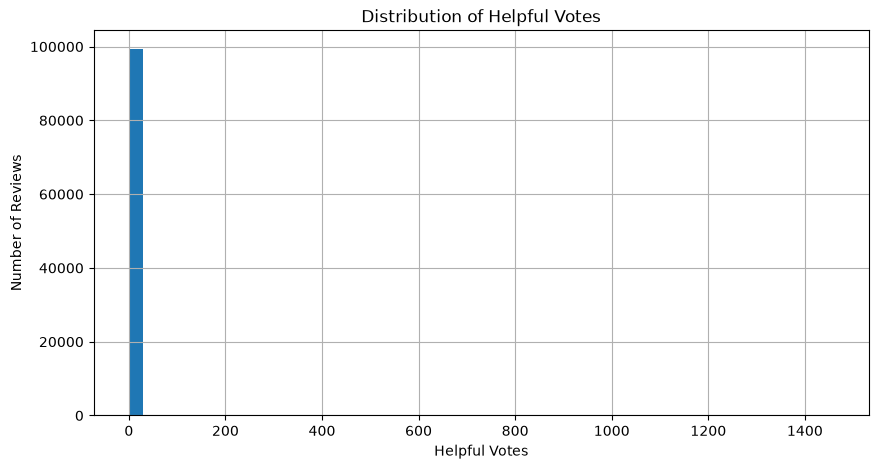

In [24]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

reviews_clean["helpful_vote"].hist(bins=50)

plt.title("Distribution of Helpful Votes")
plt.xlabel("Helpful Votes")
plt.ylabel("Number of Reviews")

plt.show()


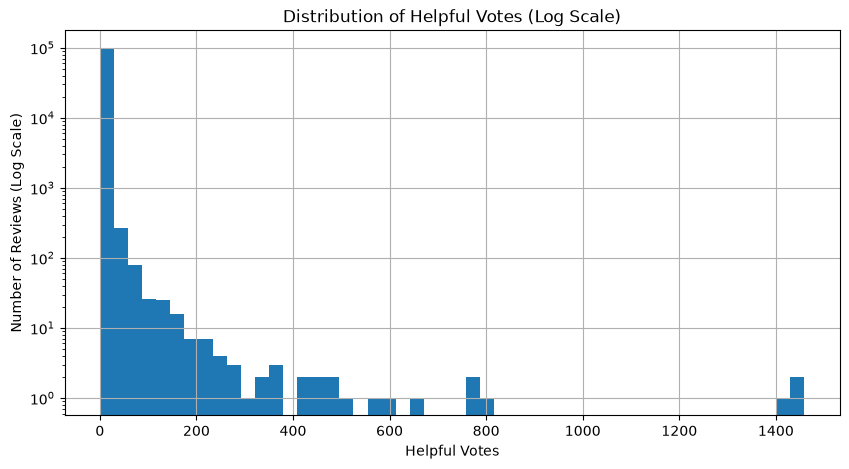

In [25]:

plt.figure(figsize=(10, 5))

reviews_clean["helpful_vote"].hist(bins=50, log=True)

plt.title("Distribution of Helpful Votes (Log Scale)")
plt.xlabel("Helpful Votes")
plt.ylabel("Number of Reviews (Log Scale)")

plt.show()


In [26]:

rating_counts = reviews_clean["rating"].value_counts().sort_index()

rating_table = pd.DataFrame({
    "Count": rating_counts,
    "Percentage": rating_counts / len(reviews_clean) * 100
})

rating_table


,Count,Percentage
rating,,
1.0,11854,11.871570
2.0,5322,5.329888
3.0,7202,7.212675
4.0,10803,10.819012
5.0,64671,64.766855


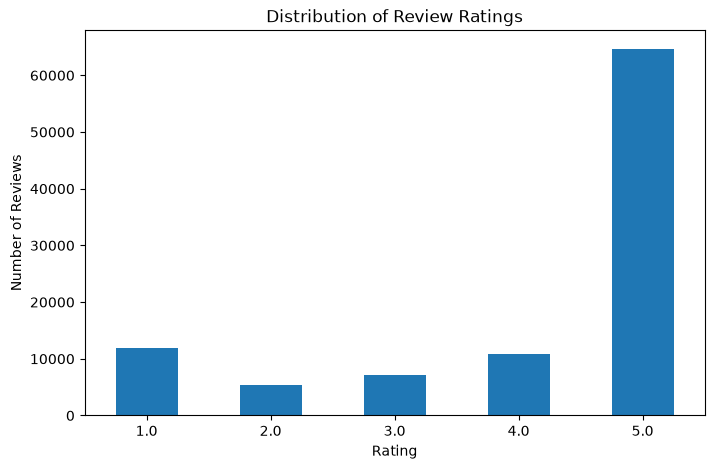

In [27]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

reviews_clean["rating"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribution of Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.show()


In [28]:

verified_counts = reviews_clean["verified_purchase"].value_counts()

verified_table = pd.DataFrame({
    "Count": verified_counts,
    "Percentage": verified_counts / len(reviews_clean) * 100
})

verified_table


,Count,Percentage
verified_purchase,,
True,90839,90.973641
False,9013,9.026359


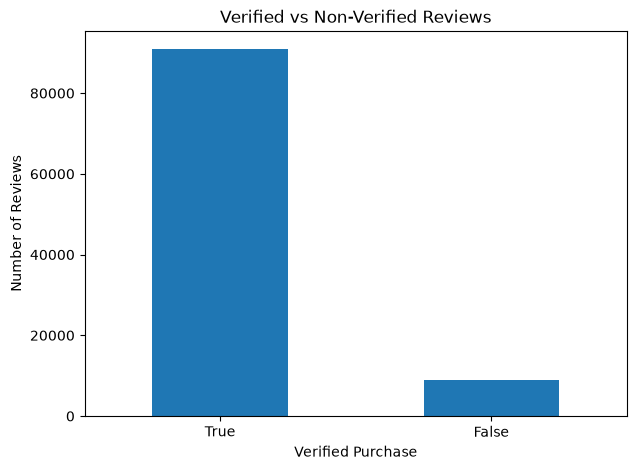

In [29]:

plt.figure(figsize=(7, 5))

reviews_clean["verified_purchase"].value_counts().plot(
    kind="bar"
)

plt.title("Verified vs Non-Verified Reviews")
plt.xlabel("Verified Purchase")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)

plt.show()


In [30]:

reviews_clean["text_length"] = reviews_clean["text"].str.len()

reviews_clean["text_length"].describe()


count    99852.000000
mean       177.716470
std        239.887403
min          1.000000
25%         46.000000
50%        108.000000
75%        219.000000
max      10116.000000
Name: text_length, dtype: float64

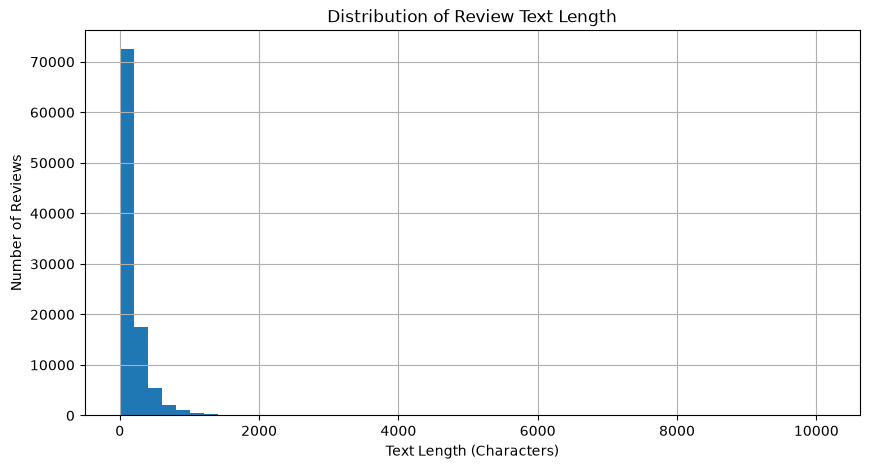

In [31]:

plt.figure(figsize=(10, 5))

reviews_clean["text_length"].hist(bins=50)

plt.title("Distribution of Review Text Length")
plt.xlabel("Text Length (Characters)")
plt.ylabel("Number of Reviews")

plt.show()


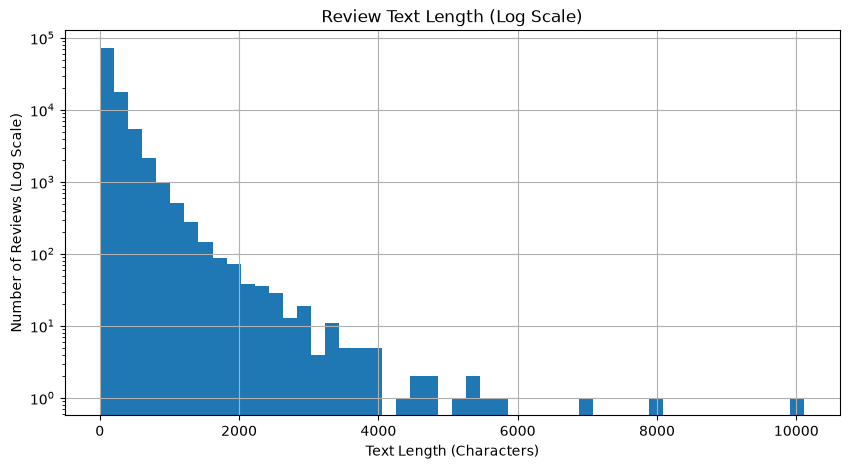

In [32]:

plt.figure(figsize=(10, 5))

reviews_clean["text_length"].hist(bins=50, log=True)

plt.title("Review Text Length (Log Scale)")
plt.xlabel("Text Length (Characters)")
plt.ylabel("Number of Reviews (Log Scale)")

plt.show()


In [33]:

meta_clean["price_numeric"].describe()


count    34009.000000
mean        25.624092
std         52.864392
min          0.000000
25%          9.990000
50%         15.990000
75%         27.000000
max       3799.000000
Name: price_numeric, dtype: float64

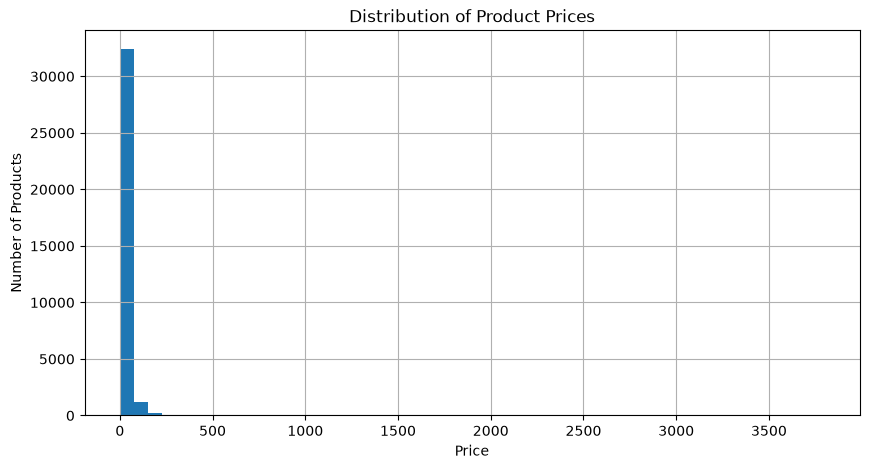

In [34]:

plt.figure(figsize=(10, 5))

meta_clean["price_numeric"].dropna().hist(bins=50)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Number of Products")

plt.show()


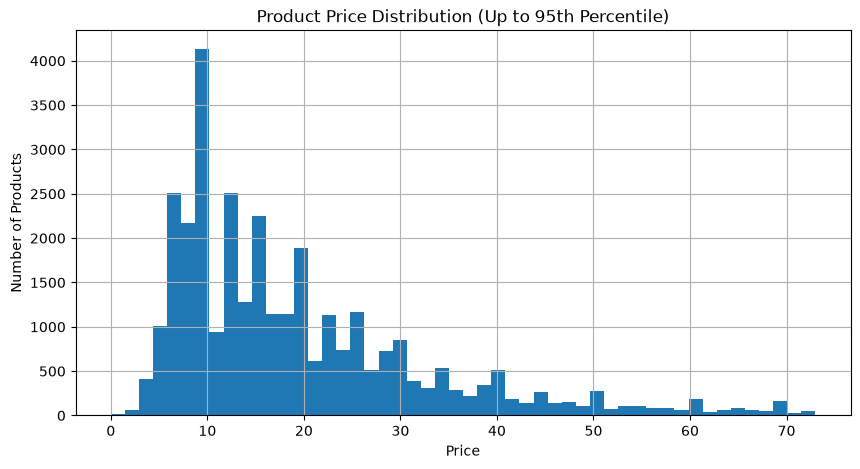

In [35]:

price_95 = meta_clean["price_numeric"].quantile(0.95)

plt.figure(figsize=(10, 5))

meta_clean.loc[
    meta_clean["price_numeric"] <= price_95,
    "price_numeric"
].hist(bins=50)

plt.title("Product Price Distribution (Up to 95th Percentile)")
plt.xlabel("Price")
plt.ylabel("Number of Products")

plt.show()


In [36]:

meta_clean["average_rating"].describe()


count    55902.000000
mean         4.247898
std          0.448858
min          1.000000
25%          4.100000
50%          4.400000
75%          4.600000
max          5.000000
Name: average_rating, dtype: float64

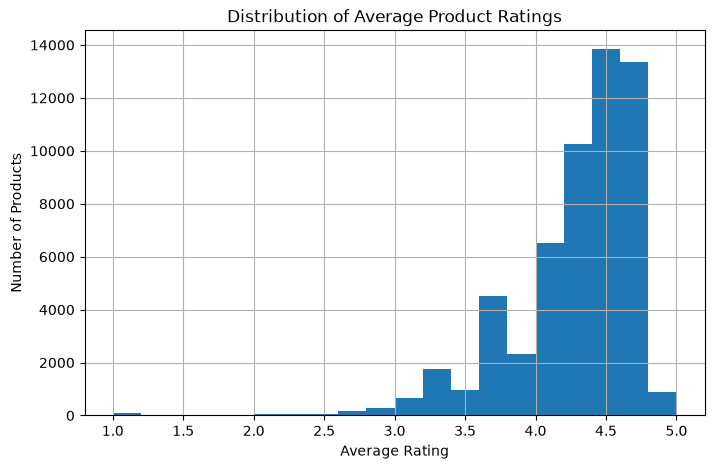

In [37]:

plt.figure(figsize=(8, 5))

meta_clean["average_rating"].hist(bins=20)

plt.title("Distribution of Average Product Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Products")

plt.show()


In [38]:

meta_clean["rating_number"].describe()


count     55902.000000
mean       1889.930790
std        5843.356077
min           1.000000
25%          88.000000
50%         388.000000
75%        1479.000000
max      340182.000000
Name: rating_number, dtype: float64

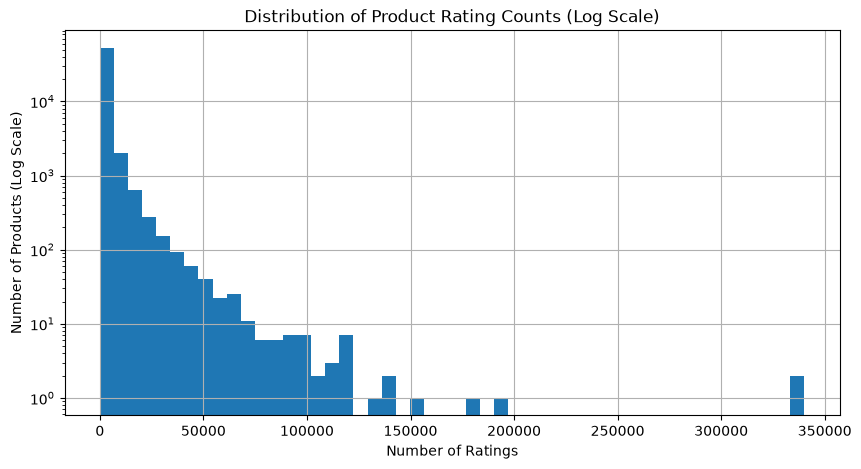

In [39]:

plt.figure(figsize=(10, 5))

meta_clean["rating_number"].hist(bins=50, log=True)

plt.title("Distribution of Product Rating Counts (Log Scale)")
plt.xlabel("Number of Ratings")
plt.ylabel("Number of Products (Log Scale)")

plt.show()


In [40]:

category_counts = meta_clean["main_category"].value_counts().head(15)

category_counts


main_category
All Beauty                  42386
Health & Personal Care       4647
Premium Beauty               3262
Unknown                      1762
Amazon Home                  1500
Tools & Home Improvement      748
AMAZON FASHION                477
Industrial & Scientific       326
Toys & Games                  132
Sports & Outdoors             115
Grocery                       112
Office Products                65
Pet Supplies                   65
Arts, Crafts & Sewing          65
All Electronics                54
Name: count, dtype: int64

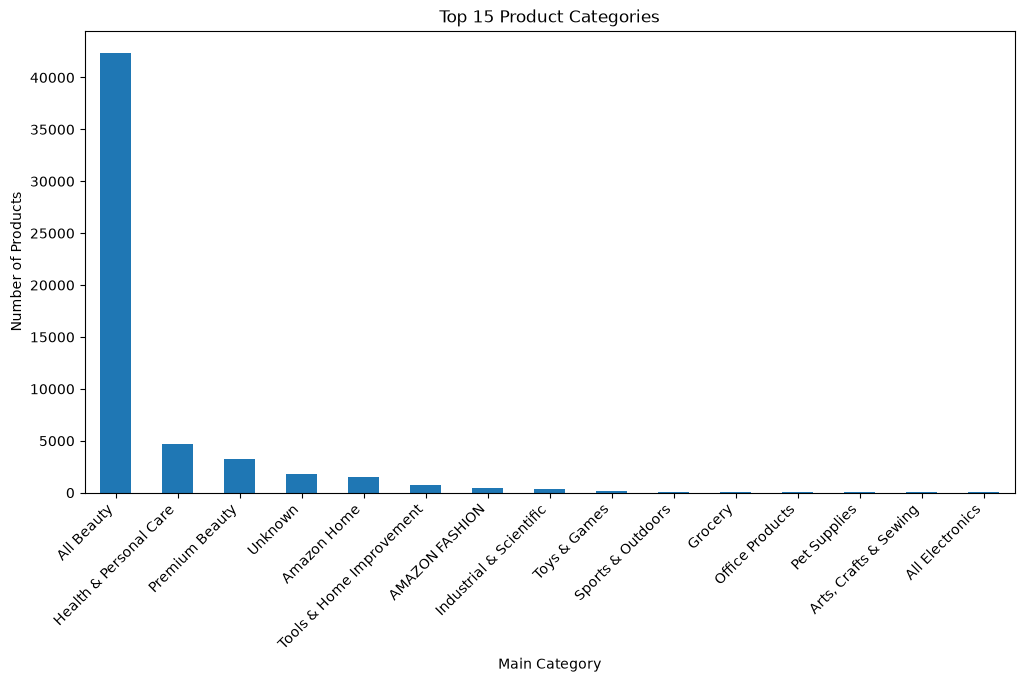

In [41]:

plt.figure(figsize=(12, 6))

category_counts.plot(kind="bar")

plt.title("Top 15 Product Categories")
plt.xlabel("Main Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha="right")

plt.show()


تحلیل چند متغییره:

In [42]:

rating_helpfulness = reviews_clean.groupby("rating")["helpful_vote"].agg(
    ["count", "mean", "median"]
)

rating_helpfulness


,count,mean,median
rating,,,
1.0,11854,1.794837,0.0
2.0,5322,0.914694,0.0
3.0,7202,1.153013,0.0
4.0,10803,1.172082,0.0
5.0,64671,1.071083,0.0


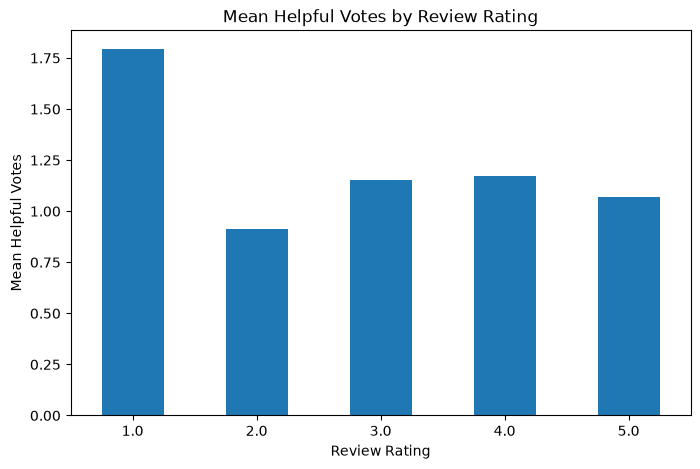

In [43]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

rating_helpfulness["mean"].plot(kind="bar")

plt.title("Mean Helpful Votes by Review Rating")
plt.xlabel("Review Rating")
plt.ylabel("Mean Helpful Votes")
plt.xticks(rotation=0)

plt.show()


In [45]:

reviews_clean["text_length_group"] = pd.cut(
    reviews_clean["text_length"],
    bins=[0,  honderd if False else 100, 300, 600, 1000, float("inf")],
    labels=["0-100", "101-300", "301-600", "601-1000", "1000+"]
)


In [46]:

length_helpfulness = reviews_clean.groupby(
    "text_length_group",
    observed=True
)["helpful_vote"].agg(["count", "mean", "median"])

length_helpfulness


,count,mean,median
text_length_group,,,
0-100,47567,0.311287,0.0
101-300,36164,1.041616,0.0
301-600,11612,2.661557,0.0
601-1000,3182,5.146763,1.0
1000+,1327,12.523738,2.0


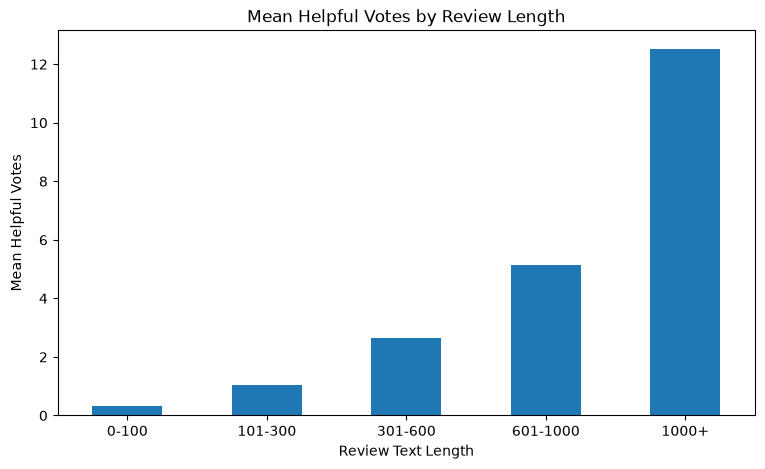

In [47]:

plt.figure(figsize=(9, 5))

length_helpfulness["mean"].plot(kind="bar")

plt.title("Mean Helpful Votes by Review Length")
plt.xlabel("Review Text Length")
plt.ylabel("Mean Helpful Votes")
plt.xticks(rotation=0)

plt.show()


In [48]:

verified_rating_helpfulness = reviews_clean.groupby(
    ["verified_purchase", "rating"]
)["helpful_vote"].agg(["count", "mean", "median"])

verified_rating_helpfulness


count      mean  median
verified_purchase rating                         
False             1.0       954  2.036688     0.0
                  2.0       477  1.079665     0.0
                  3.0       687  1.138282     0.0
                  4.0      1458  1.248971     0.0
                  5.0      5437  0.906014     0.0
True              1.0     10900  1.773670     0.0
                  2.0      4845  0.898452     0.0
                  3.0      6515  1.154566     0.0
                  4.0      9345  1.160086     0.0
                  5.0     59234  1.086234     0.0

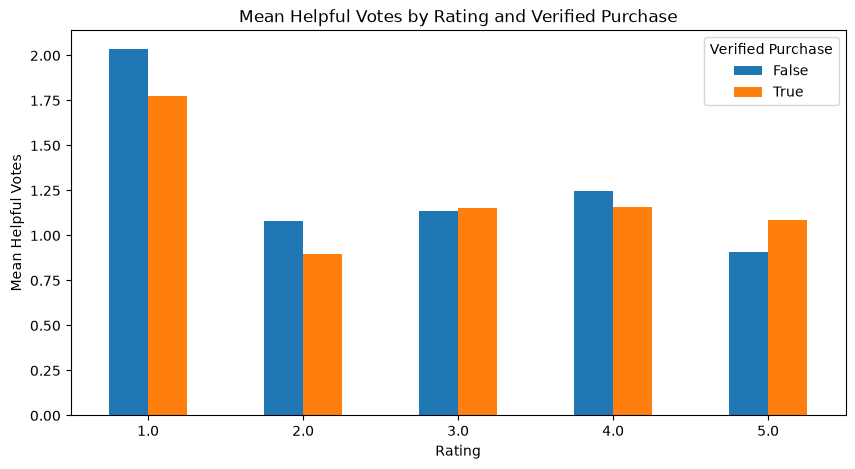

In [49]:

verified_rating_helpfulness["mean"].unstack(
    level=0
).plot(kind="bar", figsize=(10, 5))

plt.title("Mean Helpful Votes by Rating and Verified Purchase")
plt.xlabel("Rating")
plt.ylabel("Mean Helpful Votes")
plt.xticks(rotation=0)
plt.legend(title="Verified Purchase")

plt.show()


In [50]:

numeric_features = reviews_clean[
    ["rating", "helpful_vote", "text_length"]
]

correlation_matrix = numeric_features.corr(method="spearman")

correlation_matrix


,rating,helpful_vote,text_length
rating,1.000000,-0.087382,-0.124380
helpful_vote,-0.087382,1.000000,0.317316
text_length,-0.124380,0.317316,1.000000


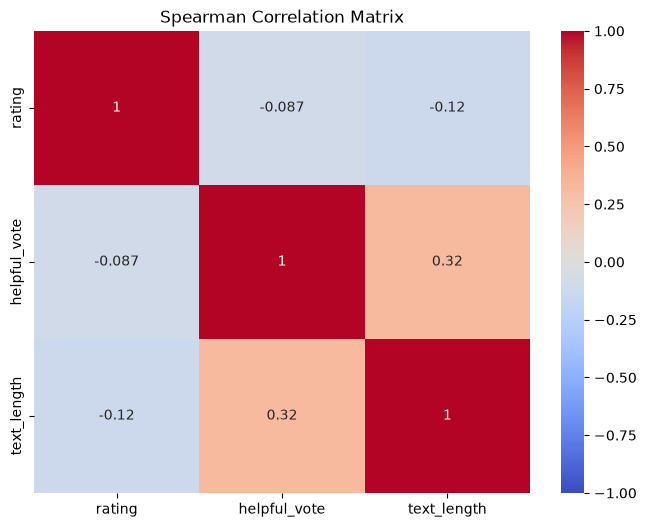

In [51]:

import seaborn as sns

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Spearman Correlation Matrix")

plt.show()


الزامات مسیر ب

تحلیل دسترسی پذیری:

In [52]:
reviews_clean["images"].apply(type).value_counts()

images
<class 'list'>    99852
Name: count, dtype: int64

In [53]:
def has_image(x):
    if isinstance(x, (list, tuple)):
        return len(x) > 0
    elif isinstance(x, str):
        return len(x.strip()) > 0
    else:
        return False

reviews_clean["has_image"] = reviews_clean["images"].apply(has_image)

In [54]:
reviews_meta = reviews_clean.merge(
    meta_clean,
    on="parent_asin",
    how="left"
)

In [55]:
availability = pd.DataFrame({
    "Modality": [
        "Text",
        "Image",
        "Rating",
        "Timestamp",
        "Product Category",
        "Product Price",
        "Product Average Rating"
    ],

    "Available": [
        reviews_meta["text"].notna().sum(),
        reviews_meta["has_image"].sum(),
        reviews_meta["rating"].notna().sum(),
        reviews_meta["timestamp"].notna().sum(),
        reviews_meta["main_category"].notna().sum(),
        reviews_meta["price_numeric"].notna().sum(),
        reviews_meta["average_rating"].notna().sum()
    ]
})

availability["Percentage"] = (
    availability["Available"] / len(reviews_meta) * 100
)

availability

,Modality,Available,Percentage
0,Text,99852,100.000000
1,Image,7004,7.014381
2,Rating,99852,100.000000
3,Timestamp,99852,100.000000
4,Product Category,99852,100.000000
5,Product Price,70050,70.153828
6,Product Average Rating,99852,100.000000


In [56]:
reviews_meta.groupby("main_category")["has_image"].mean().sort_values(ascending=False)

main_category
Movies & TV                  0.333333
All Electronics              0.127660
Amazon Home                  0.100128
Unknown                      0.095789
Office Products              0.081395
Toys & Games                 0.076923
Tools & Home Improvement     0.073408
All Beauty                   0.072706
Automotive                   0.068966
Industrial & Scientific      0.064583
AMAZON FASHION               0.060309
Baby                         0.060000
Pet Supplies                 0.055118
Health & Personal Care       0.055028
Musical Instruments          0.050000
Appliances                   0.043750
Premium Beauty               0.040139
Grocery                      0.024845
Arts, Crafts & Sewing        0.022472
Sports & Outdoors            0.019417
Cell Phones & Accessories    0.016393
Amazon Devices               0.000000
Car Electronics              0.000000
Camera & Photo               0.000000
Buy a Kindle                 0.000000
Books                        0.00000

In [57]:
reviews_meta.groupby("main_category")["price_numeric"].apply(
    lambda x: x.notna().mean() * 100
).sort_values(ascending=False)

main_category
Buy a Kindle                 100.000000
Car Electronics              100.000000
Tools & Home Improvement      77.078652
Industrial & Scientific       74.166667
Premium Beauty                71.277150
Arts, Crafts & Sewing         70.786517
All Beauty                    70.779204
Health & Personal Care        70.258096
Office Products               69.767442
Pet Supplies                  69.291339
Automotive                    68.965517
Appliances                    68.750000
Amazon Home                   67.608045
All Electronics               67.021277
Digital Music                 66.666667
Camera & Photo                66.666667
Sports & Outdoors             66.504854
AMAZON FASHION                65.918654
Toys & Games                  63.905325
Grocery                       53.416149
Unknown                       51.403799
Books                         50.000000
Baby                          50.000000
Computers                     50.000000
Home Audio & Theater      

ممیزی متن به جز بررسی طول متن که بالا انجام دادیم:


In [58]:
reviews_clean["text_length"] = reviews_clean["text"].str.len()

In [59]:
reviews_clean["text_length"].describe()

count    99852.000000
mean       177.716470
std        239.887403
min          1.000000
25%         46.000000
50%        108.000000
75%        219.000000
max      10116.000000
Name: text_length, dtype: float64

In [60]:
short_reviews = reviews_clean[
    reviews_clean["text_length"] < 20
]

print("Number of short reviews:", len(short_reviews))

print(
    "Percentage of short reviews:",
    len(short_reviews) / len(reviews_clean) * 100
)

Number of short reviews: 10250
Percentage of short reviews: 10.26519248487762


In [61]:
long_threshold = reviews_clean["text_length"].quantile(0.95)

long_reviews = reviews_clean[
    reviews_clean["text_length"] > long_threshold
]

print("95th percentile:", long_threshold)

print("Number of long reviews:", len(long_reviews))

95th percentile: 572.0
Number of long reviews: 4987


In [62]:
reviews_clean.groupby("rating")["text_length"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
rating,,,
1.0,11854,177.370255,119.0
2.0,5322,214.402104,141.0
3.0,7202,215.167592,136.0
4.0,10803,225.750532,135.0
5.0,64671,162.566374,95.0


In [63]:
reviews_clean[["rating", "text_length"]].corr(method="spearman")

,rating,text_length
rating,1.00000,-0.12438
text_length,-0.12438,1.00000


In [64]:
reviews_clean["non_ascii_ratio"] = reviews_clean["text"].apply(
    lambda x: sum(ord(char) > 127 for char in x) / len(x)
    if len(x) > 0 else 0
)

In [65]:
reviews_clean["non_ascii_ratio"].describe()

count    99852.000000
mean         0.003250
std          0.033175
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          1.000000
Name: non_ascii_ratio, dtype: float64

In [66]:
non_ascii_reviews = reviews_clean[
    reviews_clean["non_ascii_ratio"] > 0
]

print("Count:", len(non_ascii_reviews))

print("Percentage:", len(non_ascii_reviews) / len(reviews_clean) * 100)

Count: 15464
Percentage: 15.486920642550976


In [68]:
reviews_clean.loc[
    reviews_clean["non_ascii_ratio"] == 1,
    ["rating", "text"]
].head(10)

,rating,text
860,4.0,👍🏽
3263,5.0,👍🏾
6456,5.0,🤗
6677,5.0,👍🏼
6796,5.0,😀
6959,5.0,🦾
12405,5.0,👍
13062,4.0,😀
13301,5.0,👍
14010,5.0,👍
